<a href="https://colab.research.google.com/github/nthsneha/AI-Revenue-Recovery-/blob/main/models/viability_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [48]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [58]:
df_user = pd.read_csv("/content/AI-Revenue-Recovery-/dataset/user_history.csv")
df_failures = pd.read_csv("/content/AI-Revenue-Recovery-/dataset/implicit_failures.csv")

In [59]:
df_user.info(), df_failures.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 10 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   user_id                       300 non-null    object 
 1   total_orders                  300 non-null    int64  
 2   successful_payments           300 non-null    int64  
 3   failed_payments               300 non-null    int64  
 4   avg_order_value               300 non-null    float64
 5   preferred_payment_method      300 non-null    object 
 6   preferred_channel             300 non-null    object 
 7   last_successful_payment_days  300 non-null    int64  
 8   churn_risk_score              300 non-null    float64
 9   is_subscribed                 300 non-null    bool   
dtypes: bool(1), float64(2), int64(4), object(3)
memory usage: 21.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Colu

(None, None)

<h4>Conclusion: Dataset is clean and has no null values </h4>



---

<h2>Data Cleaning</h2>


In [75]:
df = pd.merge(df_failures, df_user, how = 'left', on = 'user_id')

In [76]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   event_id                      1000 non-null   object 
 1   user_id                       1000 non-null   object 
 2   revenue_loss_mode             1000 non-null   object 
 3   amount_at_risk                1000 non-null   float64
 4   time_since_last_action        1000 non-null   int64  
 5   user_intent_score             1000 non-null   float64
 6   device_type                   1000 non-null   object 
 7   time_of_day                   1000 non-null   object 
 8   is_valuable_customer          1000 non-null   bool   
 9   target_recovered              1000 non-null   int64  
 10  total_orders                  1000 non-null   int64  
 11  successful_payments           1000 non-null   int64  
 12  failed_payments               1000 non-null   int64  
 13  avg_

In [77]:
#Feature Engineering
df['payment_reliability'] = df['successful_payments']/df['total_orders']

In [78]:
#dropping event_id, user_id
df.drop(columns = ['user_id', 'event_id'], inplace = True)

In [79]:
#one hot encoding for categorical features
cols = [
        'revenue_loss_mode', 'device_type', 'time_of_day',
        'preferred_payment_method', 'preferred_channel'
]

for col in cols:
    df[col] = df[col].astype('category')

In [80]:
# Drops the column and assigns the resulting dataframe to X
X = df.drop(columns = ['target_recovered'])
y = df['target_recovered']

# Now your split will work
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, stratify=y)

<h2>Training Model</h2>

In [81]:
import xgboost as xgb

In [99]:
model = xgb.XGBClassifier(
        n_estimators=150,
        max_depth=3,
        learning_rate=0.1,
        use_label_encoder=False,
        eval_metric='logloss',
        enable_categorical=True
)

model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/xgboost/training.py:200: UserWarning: [19:20:34] WARNING: /__w/xgboost/xgboost/src/learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=3, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=None,
              num_parallel_tree=None, ...)

In [100]:
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:,1]

In [101]:
y_pred, y_pred_proba

(array([0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1,
        0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1,
        0, 1, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1,
        0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1,
        1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0,
        0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0,
        1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1,
        0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0,
        1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1,
        1, 0]),
 array([2.93439150e-01, 6.60814404e-01, 7.68396676e-01, 2.85286386e-03,
        4.95455973e-02, 1.43572673e-01, 9.91683602e-01, 2.46220753e-02,
        1.58894639e-02, 4.97773625e-02, 1.81443766e-02, 3.93021107e-01,
        8.60326632e-04, 6.64719880e-01, 2.68910587e-01, 2.63685430e-03,
        9.03029621e-01, 1.7394

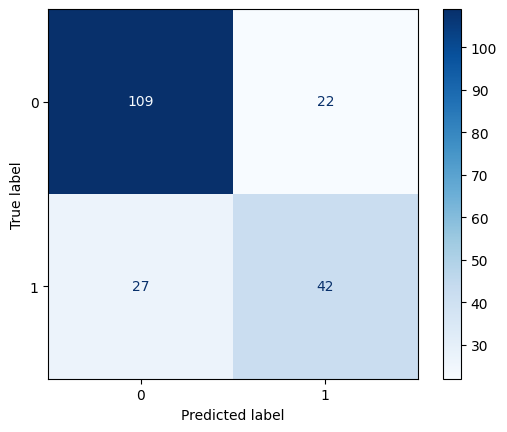

In [102]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')

#Display the plot
plt.show()

In [103]:
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1 Score: {f1:.4f}")

Precision: 0.6562
Recall: 0.6087
F1 Score: 0.6316
